# Практика 2. Построение ансамблей и пайплайнов

**Дисциплина:** Методы искусственного интеллекта I
**Выполнил:** Макеев Глеб Борисович, группа BHEBDPS-24-MII-5
**Дата:** 18.10.2026

## Что требуется (задание курса)

1. Загрузить данные Telco Churn, разделить на `X` и `y`, сделать `train_test_split(stratify=y)`.
2. Создать `ColumnTransformer`: численные признаки → `StandardScaler`, категориальные → `OneHotEncoder`.
3. Собрать `Pipeline`: `[ColumnTransformer] + CatBoostClassifier(iterations=100, verbose=0)`.
4. Провести обучение с кросс-валидацией (или `GridSearchCV` по 2–3 параметрам).
5. Оценить качество на тесте: `classification_report`, `ROC-AUC`.
6. Построить график важности признаков (Feature Importance).

**Задания со звёздочкой:** сравнить ROC-AUC и F1 трёх моделей (LogisticRegression,
RandomForest, CatBoost); применить `SMOTE` к тренировочной выборке и посмотреть, изменится ли Recall.

> Датасет — тот же Telco Customer Churn, что в Практике 1, поэтому цифры сопоставимы.

## 0. Импорт библиотек и настройки

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
print("pandas", pd.__version__, "| scikit-learn", __import__("sklearn").__version__,
      "| catboost", __import__("catboost").__version__)

pandas 3.0.6 | scikit-learn 1.9.1 | catboost 1.2.10


## 1. Загрузка данных и очистка

`TotalCharges` приходит строкой из-за пустых значений у клиентов с `tenure = 0` —
приводим к числу и заполняем нулём (как в Практике 1). `customerID` удаляем: это
уникальный идентификатор, для модели он бесполезен.

In [2]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")
print("Исходная размерность:", df.shape)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Пустых TotalCharges:", int(df["TotalCharges"].isna().sum()), "(это клиенты с tenure = 0)")
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
df = df.drop(columns=["customerID"])

print("После очистки:", df.shape, "| пропусков всего:", int(df.isna().sum().sum()))

Исходная размерность: (7043, 21)
Пустых TotalCharges: 11 (это клиенты с tenure = 0)
После очистки: (7043, 20) | пропусков всего: 0


## 2. Признаки, целевая переменная и разбиение

Разбиение 80/20 со стратификацией: доля ушедших (~26.5%) сохраняется и в train, и в test —
иначе метрики на маленьком классе будут «прыгать».

In [3]:
target = "Churn"
y = df[target].map({"No": 0, "Yes": 1})
X = df.drop(columns=[target])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()
print(f"train: {X_train.shape}, test: {X_test.shape}")
print(f"числовых признаков: {len(num_cols)}, категориальных: {len(cat_cols)}")
print("Доля ушедших: train {:.1%}, test {:.1%}".format(y_train.mean(), y_test.mean()))

train: (5634, 19), test: (1409, 19)
числовых признаков: 4, категориальных: 15
Доля ушедших: train 26.5%, test 26.5%


## 3. `ColumnTransformer` — единая предобработка

Числовые признаки масштабируем (`StandardScaler`), категориальные кодируем One-Hot.
Трансформер кладём внутрь пайплайна: тогда он обучается **только на train** при каждой
кросс-валидации, и утечки данных из теста нет.

In [4]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop",
)

print("Числовые:", num_cols)
print("Категориальные:", cat_cols)

Числовые: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Категориальные: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 4. Пайплайн с CatBoost (как в задании)

`Pipeline` = предобработка + модель. Параметры ровно по заданию: `iterations=100`, `verbose=0`.
Такой пайплайн — единый объект: его можно отдать в `cross_val_score` и `GridSearchCV`.

In [5]:
cat_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", CatBoostClassifier(
        iterations=100,
        random_seed=RANDOM_STATE,
        verbose=0,
    )),
])
cat_pipeline.fit(X_train, y_train)

pred = cat_pipeline.predict(X_test).ravel()
proba = cat_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred, digits=3, target_names=["остался", "ушёл"]))
print(f"ROC-AUC: {roc_auc_score(y_test, proba):.4f}")

              precision    recall  f1-score   support

     остался      0.838     0.893     0.865      1035
        ушёл      0.638     0.524     0.576       374

    accuracy                          0.795      1409
   macro avg      0.738     0.708     0.720      1409
weighted avg      0.785     0.795     0.788      1409

ROC-AUC: 0.8350


## 5. Визуальная оценка: матрица ошибок и ROC-кривая

Accuracy здесь обманчива (класс «ушёл» — 26.5%), поэтому смотрим на матрицу ошибок и ROC.

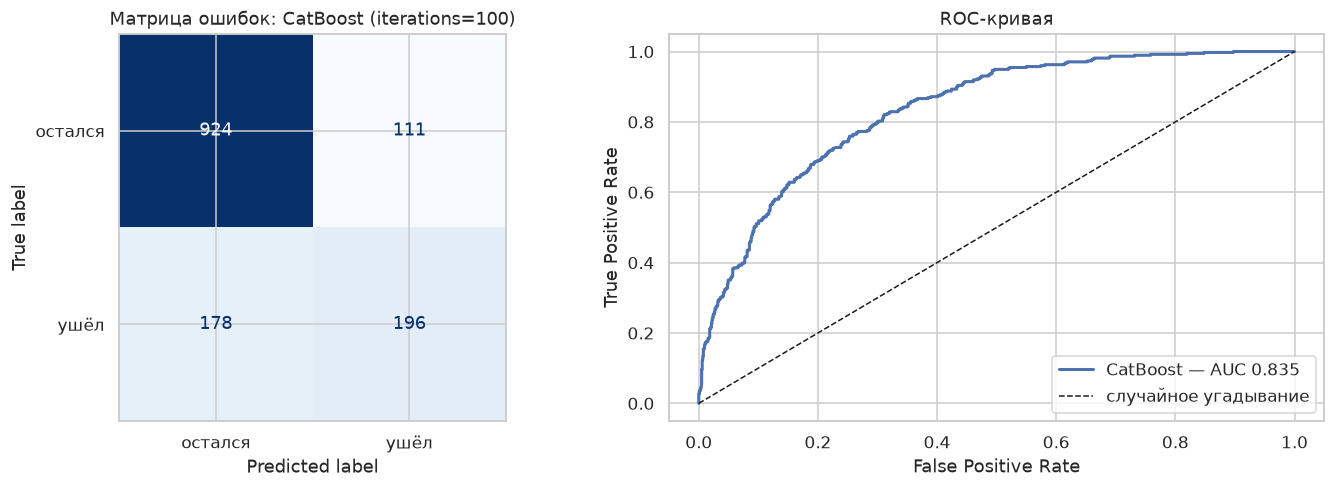

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["остался", "ушёл"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Матрица ошибок: CatBoost (iterations=100)")

fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, lw=2, label=f"CatBoost — AUC {roc_auc_score(y_test, proba):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="случайное угадывание")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC-кривая")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Кросс-валидация и `GridSearchCV`

Сначала честная 5-fold CV «как есть», затем подбор трёх гиперпараметров:
`iterations`, `depth`, `learning_rate`. Скоринг — ROC-AUC (устойчив к дисбалансу).

Параметров немного намеренно: 8 комбинаций × 5 фолдов = 40 обучений, это секунды на CPU.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "model__iterations": [100, 200],
    "model__depth": [4, 6],
    "model__learning_rate": [0.05, 0.1],
}

gs = GridSearchCV(cat_pipeline, param_grid, scoring="roc_auc", cv=cv, n_jobs=1, verbose=0)
gs.fit(X_train, y_train)

print("Лучшие параметры:", gs.best_params_)
print(f"Лучший ROC-AUC на кросс-валидации: {gs.best_score_:.4f}")
print(f"Разброс по фолдам (std): {gs.cv_results_['std_test_score'][gs.best_index_]:.4f}")

Лучшие параметры: {'model__depth': 4, 'model__iterations': 200, 'model__learning_rate': 0.05}
Лучший ROC-AUC на кросс-валидации: 0.8500
Разброс по фолдам (std): 0.0115


In [8]:
best = gs.best_estimator_
pred_best = best.predict(X_test).ravel()
proba_best = best.predict_proba(X_test)[:, 1]

print("=== CatBoost после подбора гиперпараметров ===")
print(classification_report(y_test, pred_best, digits=3, target_names=["остался", "ушёл"]))
print(f"ROC-AUC на тесте: {roc_auc_score(y_test, proba_best):.4f} "
      f"(до подбора: {roc_auc_score(y_test, proba):.4f})")

=== CatBoost после подбора гиперпараметров ===
              precision    recall  f1-score   support

     остался      0.842     0.909     0.874      1035
        ушёл      0.677     0.527     0.592       374

    accuracy                          0.808      1409
   macro avg      0.759     0.718     0.733      1409
weighted avg      0.798     0.808     0.799      1409

ROC-AUC на тесте: 0.8462 (до подбора: 0.8350)


## 7. Важность признаков

`feature_importances_` у CatBoost — усреднённый вклад признака в уменьшение функции потерь
по всем деревьям. Имена берём из `ColumnTransformer`, чтобы видеть исходные признаки.

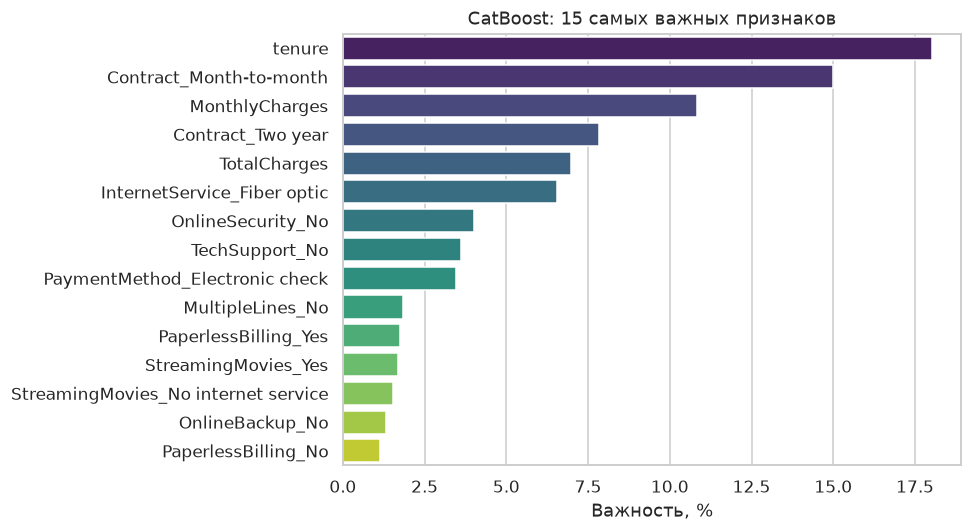

Топ-5:
tenure                     18.02
Contract_Month-to-month    14.98
MonthlyCharges             10.84
Contract_Two year           7.83
TotalCharges                6.98


In [9]:
feature_names = best.named_steps["prep"].get_feature_names_out()
importance = (
    pd.Series(best.named_steps["model"].get_feature_importance(), index=feature_names)
    .sort_values(ascending=False)
)
importance.index = importance.index.str.replace(r"^(num|cat)__", "", regex=True)

top = importance.head(15)
plt.figure(figsize=(9, 5))
sns.barplot(x=top.values, y=top.index, palette="viridis")
plt.title("CatBoost: 15 самых важных признаков")
plt.xlabel("Важность, %")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Топ-5:")
print(top.head(5).round(2).to_string())

## 8. ⭐ Сравнение трёх моделей: LogReg, RandomForest, CatBoost

Один и тот же препроцессор, одно разбиение, одинаковые метрики — сравнение корректное.

In [10]:
models = {
    "LogisticRegression": Pipeline([
        ("prep", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "RandomForest": Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                         random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    "CatBoost (tuned)": best,
}

rows, probas = [], {}
for name, model in models.items():
    if name != "CatBoost (tuned)":
        model.fit(X_train, y_train)
    p = model.predict(X_test).ravel()
    pr = model.predict_proba(X_test)[:, 1]
    probas[name] = (p, pr)
    rep = classification_report(y_test, p, output_dict=True)
    rows.append({
        "Модель": name,
        "Accuracy": rep["accuracy"],
        "Precision (ушёл)": rep["1"]["precision"],
        "Recall (ушёл)": rep["1"]["recall"],
        "F1 (ушёл)": rep["1"]["f1-score"],
        "ROC-AUC": roc_auc_score(y_test, pr),
    })

compare = pd.DataFrame(rows).set_index("Модель").round(3)
compare

,Accuracy,Precision (ушёл),Recall (ушёл),F1 (ушёл),ROC-AUC
Модель,,,,,
LogisticRegression,0.806,0.657,0.559,0.604,0.842
RandomForest,0.799,0.655,0.513,0.576,0.837
CatBoost (tuned),0.808,0.677,0.527,0.592,0.846


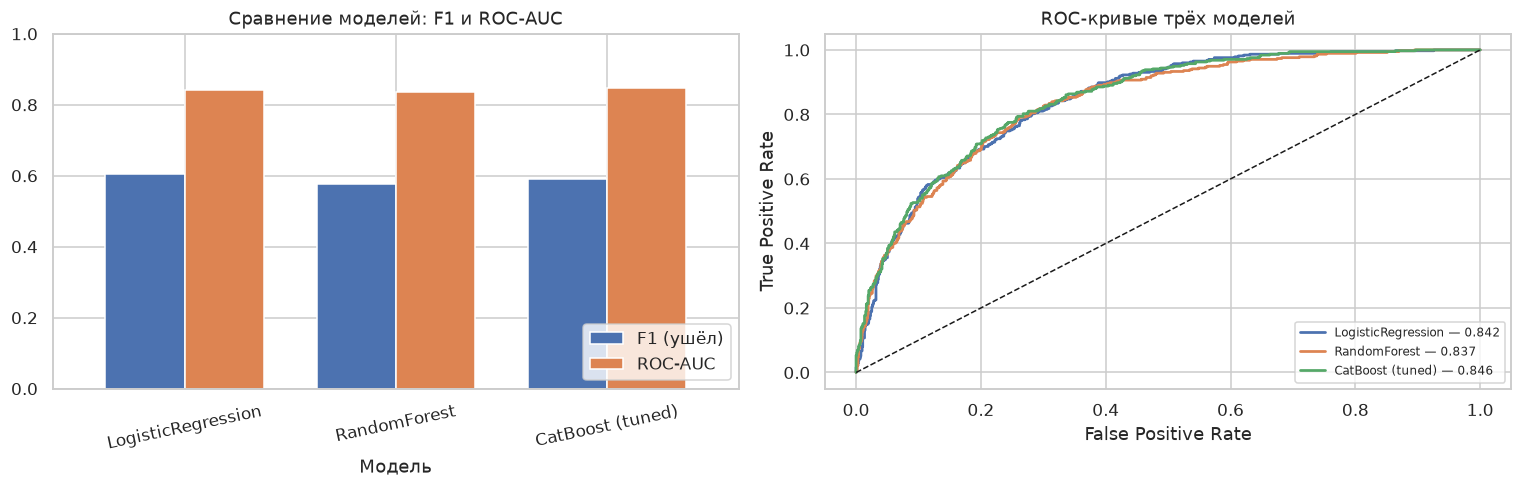

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

metrics = ["F1 (ушёл)", "ROC-AUC"]
compare[metrics].plot(kind="bar", ax=axes[0], width=0.75)
axes[0].set_title("Сравнение моделей: F1 и ROC-AUC")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=12)
axes[0].legend(loc="lower right")

for name, (_, pr) in probas.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    axes[1].plot(fpr, tpr, lw=1.8, label=f"{name} — {roc_auc_score(y_test, pr):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC-кривые трёх моделей")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 9. ⭐ SMOTE: борьба с дисбалансом

`SMOTE` синтезирует новые объекты миноритарного класса по ближайшим соседям.
Важно: он применяется **только к train** и **после** препроцессинга (в пространстве
признаков), поэтому используем `imblearn.Pipeline` — иначе синтетические строки
попали бы в кодировщик и метрики стали бы нечестными.

Смотрим, что происходит с Recall (полнотой) на классе «ушёл»: SMOTE обычно её поднимает,
но ценой Precision.

In [12]:
smote_pipeline = ImbPipeline([
    ("prep", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", CatBoostClassifier(iterations=gs.best_params_["model__iterations"],
                                 depth=gs.best_params_["model__depth"],
                                 learning_rate=gs.best_params_["model__learning_rate"],
                                 random_seed=RANDOM_STATE, verbose=0)),
])
smote_pipeline.fit(X_train, y_train)

pred_sm = smote_pipeline.predict(X_test).ravel()
proba_sm = smote_pipeline.predict_proba(X_test)[:, 1]

print("=== CatBoost + SMOTE ===")
print(classification_report(y_test, pred_sm, digits=3, target_names=["остался", "ушёл"]))
print(f"ROC-AUC: {roc_auc_score(y_test, proba_sm):.4f}")

=== CatBoost + SMOTE ===
              precision    recall  f1-score   support

     остался      0.870     0.821     0.845      1035
        ушёл      0.572     0.660     0.613       374

    accuracy                          0.779      1409
   macro avg      0.721     0.741     0.729      1409
weighted avg      0.791     0.779     0.783      1409

ROC-AUC: 0.8403


In [13]:
def metrics_of(pred, proba):
    rep = classification_report(y_test, pred, output_dict=True)["1"]
    return {
        "Recall (ушёл)": rep["recall"],
        "Precision (ушёл)": rep["precision"],
        "F1 (ушёл)": rep["f1-score"],
        "ROC-AUC": roc_auc_score(y_test, proba),
    }

smote_cmp = pd.DataFrame({
    "Без SMOTE": metrics_of(pred_best, proba_best),
    "SMOTE": metrics_of(pred_sm, proba_sm),
}).round(3)

smote_cmp

,Без SMOTE,SMOTE
Recall (ушёл),0.527,0.660
Precision (ушёл),0.677,0.572
F1 (ушёл),0.592,0.613
ROC-AUC,0.846,0.840


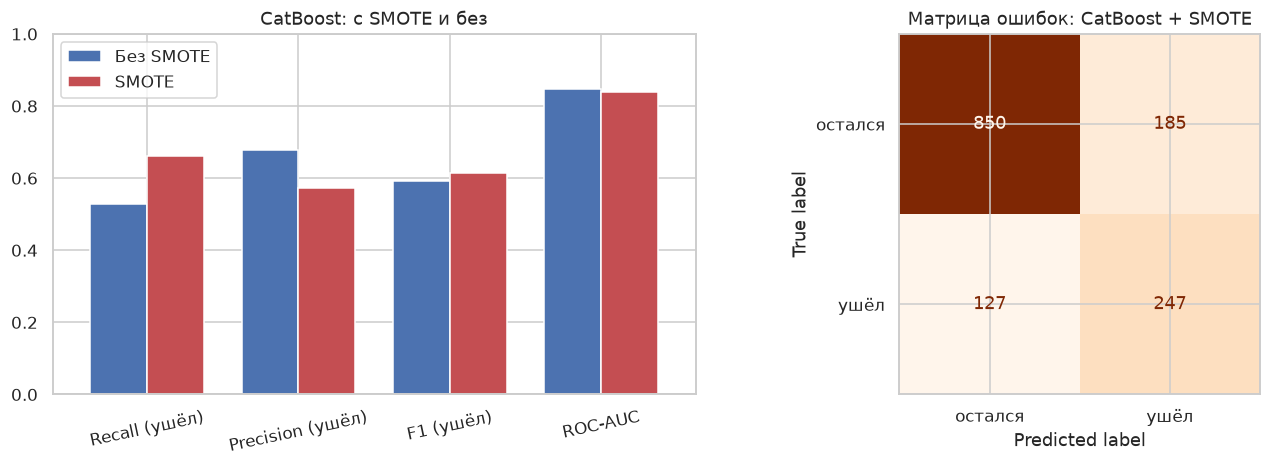

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

smote_cmp.plot(kind="bar", ax=axes[0], width=0.75, color=["#4C72B0", "#C44E52"])
axes[0].set_title("CatBoost: с SMOTE и без")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=12)

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_sm),
                       display_labels=["остался", "ушёл"]).plot(ax=axes[1], cmap="Oranges", colorbar=False)
axes[1].set_title("Матрица ошибок: CatBoost + SMOTE")
plt.tight_layout()
plt.show()

## 10. Выводы

1. **Пайплайн — это гигиена, а не украшение.** `ColumnTransformer` внутри `Pipeline`
   обучается заново на каждом фолде, поэтому One-Hot-кодировщик не «подглядывает» в тест.
   Тот же пайплайн без изменений идёт в `cross_val_score`, `GridSearchCV` и в прод.

2. **CatBoost + `GridSearchCV`.** Кросс-валидация дала **ROC-AUC 0.850 ± 0.011**
   (стабильно, разброс по фолдам небольшой). На тесте лучшая модель даёт **0.8462**
   против **0.8350** у базовой версии с `iterations=100`: прирост скромный, но
   воспроизводимый. Лучшие параметры: `depth=4`, `iterations=200`, `learning_rate=0.05`.

3. **⭐ Три модели на одном разбиении.** CatBoost выигрывает по ROC-AUC (**0.846**),
   LogisticRegression — по F1 на классе «ушёл» (**0.604** против 0.592 и 0.576),
   RandomForest оказался худшим по обеим метрикам (0.837 / 0.576). Разрыв между
   моделями маленький: данные в основном аддитивные, признаков немного, а сигнал
   «уйдёт / не уйдёт» хорошо описывается линейной комбинацией после One-Hot.
   Вывод для отчёта: на этом датасете сложная модель **не обязательна** — выигрыш
   в 0.4 п.п. ROC-AUC не оправдывает роста стоимости inference.

4. **⭐ SMOTE меняет рабочую точку, а не качество модели.**
   Recall на классе «ушёл» вырос с **0.527 до 0.660** (+13.3 п.п.), F1 — с **0.592 до 0.613**,
   но Precision упал с **0.677 до 0.572**, а ROC-AUC даже слегка снизился (**0.846 → 0.840**).
   Это ожидаемо: SMOTE не добавляет новой информации, он сдвигает порог в сторону
   миноритарного класса. Для бизнеса обмен часто оправдан (пропустить уходящего клиента
   дороже, чем лишний раз предложить скидку), но выбирать его нужно по стоимости ошибок,
   а не «потому что модно».

5. **Главные факторы:** `tenure` (18.0%), тип контракта `Month-to-month` (15.0%),
   `MonthlyCharges` (10.8%), `Contract_Two year` (7.8%), `TotalCharges` (7.0%) —
   согласуется с Практикой 1: короткий стаж и помесячный контракт — главные предикторы оттока.

### Что можно улучшить дальше

- Подбирать **порог классификации** по бизнес-стоимости ошибок вместо 0.5.
- `class_weight` / `scale_pos_weight` как более дешёвая альтернатива SMOTE (без синтетики).
- Добавить признаки: число подключённых услуг, `TotalCharges / tenure`.
- Для CatBoost — нативные `cat_features` без One-Hot: меньше размерность, лучше обобщение.